# Random Forest profitability model

This notebook uses a simple sequence: load data, split data, fill missing values, train a Random Forest, choose a validation threshold, evaluate the test data, and plot the results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, average_precision_score, classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

## Load and inspect the prepared records

The CSV has 150 predictor columns and the binary `profitable` target. Profit is 1 and Loss is 0. The classes are balanced because the source data was undersampled.

In [2]:
df = pd.read_csv("../dataset/clean_undersampled.csv", low_memory=False)
X = df.drop(columns=["profitable"])
y = df["profitable"]
print("Feature shape:", X.shape)
print("Class balance:\n", y.value_counts())

Feature shape: (549174, 150)
Class balance:
 profitable
0    274587
1    274587
Name: count, dtype: int64


## Create training, validation, and test sets

The test set is held out until the end. The validation set is used to choose the probability threshold. Stratification keeps the Profit/Loss proportions consistent.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=12, stratify=y)
X_fit, X_validation, y_fit, y_validation = train_test_split(X_train, y_train, test_size=0.20, random_state=12, stratify=y_train)
print("Training rows:", len(X_fit))
print("Validation rows:", len(X_validation))
print("Test rows:", len(X_test))

Training rows: 351471
Validation rows: 87868
Test rows: 109835


## Fill missing values and train the Random Forest

In order to fine tune the parameters that were used in the RandomForestClassifier function, a RandomizedSearchCV was first used to compare different combinations such as the number of trees, the maximum depth, and the minimum rows needed to justify a leaf prediction. 12 randomly selected combinations of settings were attempted, each implementing k-fold validation to compare the probability ranking of each forest. Based on those results, the following parameters were chosen for faster training time on future tweaks.

The active model uses the previously selected values: 250 trees, depth 24, leaf 20, split 40, max_features 0.25, Gini criterion, and max_samples 0.5.

The code can be viewed in the commented cell below. It is currently commented so the other code can be run as simply as possible.

In [4]:
# search_pipeline = Pipeline([
#     ("imputer", SimpleImputer(strategy="median")),
#     ("model", RandomForestClassifier(bootstrap=True, max_samples=0.5, random_state=12, n_jobs=-1)),
# ])
# settings_to_test = {
#     "model__n_estimators": [150, 250],  # Number of trees.
#     "model__max_depth": [12, 16, 20, 24],  # Maximum depth of each tree.
#     "model__min_samples_leaf": [20, 50, 100],  # Minimum rows in a leaf.
#     "model__min_samples_split": [40, 100],  # Minimum rows needed to split.
#     "model__max_features": ["sqrt", 0.15, 0.25],  # Features considered at each split.
#     "model__criterion": ["gini", "entropy"],  # Split-quality formula.
# }
# search = RandomizedSearchCV(
#     search_pipeline,
#     settings_to_test,
#     n_iter=12,  # Try 12 randomly selected combinations.
#     cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=12),  # Five validation folds.
#     scoring="average_precision",  # Compare probability ranking with AP.
#     random_state=12,
#     n_jobs=1,  # Each forest already uses all available cores.
# )
# search.fit(X_train, y_train)  # The best result can be read with search.best_params_.

In [5]:
imputer = SimpleImputer(strategy="median")
X_fit_imputed = imputer.fit_transform(X_fit)
X_validation_imputed = imputer.transform(X_validation)
model = RandomForestClassifier(n_estimators=250, max_depth=24, min_samples_leaf=20, min_samples_split=40, max_features=0.25, criterion="gini", max_samples=0.5, bootstrap=True, random_state=12, n_jobs=-1)
model.fit(X_fit_imputed, y_fit)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",24
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",40
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.25
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",12
,"max_samples max_samples: int or float, default=NoneIf bootstrap is True, the number of samples to draw from Xto train each base estimator.- If None (default), then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples... versionadded:: 0.22.. versionchanged:: 1.9 Float `max_samples` is relative to `sample_weight.sum()` instead of `X.shape[0]` for weighted samples.",0.5
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_l

## Choose a precision-oriented threshold

The model gives each row a Profit probability. F0.5 gives precision more weight than recall, so the selected threshold emphasizes avoiding false-positive Profit predictions.

In [6]:
validation_probability = model.predict_proba(X_validation_imputed)[:, 1]
precision_values, recall_values, thresholds = precision_recall_curve(y_validation, validation_probability)
f05_values = (1 + 0.5**2) * precision_values[:-1] * recall_values[:-1] / (0.5**2 * precision_values[:-1] + recall_values[:-1] + 1e-12)
best_index = np.argmax(f05_values)
selected_threshold = thresholds[best_index]
validation_prediction = (validation_probability >= selected_threshold).astype(int)

print("Selected threshold:", round(selected_threshold, 4))
print("Validation accuracy:", round(accuracy_score(y_validation, validation_prediction), 4))
print("Validation precision:", round(precision_values[best_index], 4))
print("Validation recall:", round(recall_values[best_index], 4))

Selected threshold: 0.5334
Validation accuracy: 0.6681
Validation precision: 0.6959
Validation recall: 0.5972


## Evaluate the held-out test data

After having used cross validation to select parameters, the model can be trained as follows.

The imputer simply addresses values with missing data. If a cell is missing data, the RandomForestClassifier will use the median of that column before fitting the forest.

In [7]:
full_imputer = SimpleImputer(strategy="median")
X_train_imputed = full_imputer.fit_transform(X_train)
X_test_imputed = full_imputer.transform(X_test)
model.fit(X_train_imputed, y_train)
test_probability = model.predict_proba(X_test_imputed)[:, 1]
test_prediction = (test_probability >= selected_threshold).astype(int)

print("Accuracy:", round(accuracy_score(y_test, test_prediction), 4))
print("Precision:", round(precision_score(y_test, test_prediction, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_prediction, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, test_prediction, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probability), 4))
print("Average precision:", round(average_precision_score(y_test, test_probability), 4))
print(classification_report(y_test, test_prediction, target_names=["Loss", "Profit"], zero_division=0))

Accuracy: 0.6677
Precision: 0.695
Recall: 0.5976
F1-score: 0.6426
ROC-AUC: 0.7325
Average precision: 0.7284
              precision    recall  f1-score   support

        Loss       0.65      0.74      0.69     54917
      Profit       0.70      0.60      0.64     54918

    accuracy                           0.67    109835
   macro avg       0.67      0.67      0.67    109835
weighted avg       0.67      0.67      0.67    109835



## Plot the test results

The first three plots show classification performance. The fourth plot shows which features the Random Forest used most often to split the data. Feature importance is not proof that a feature causes profitability.

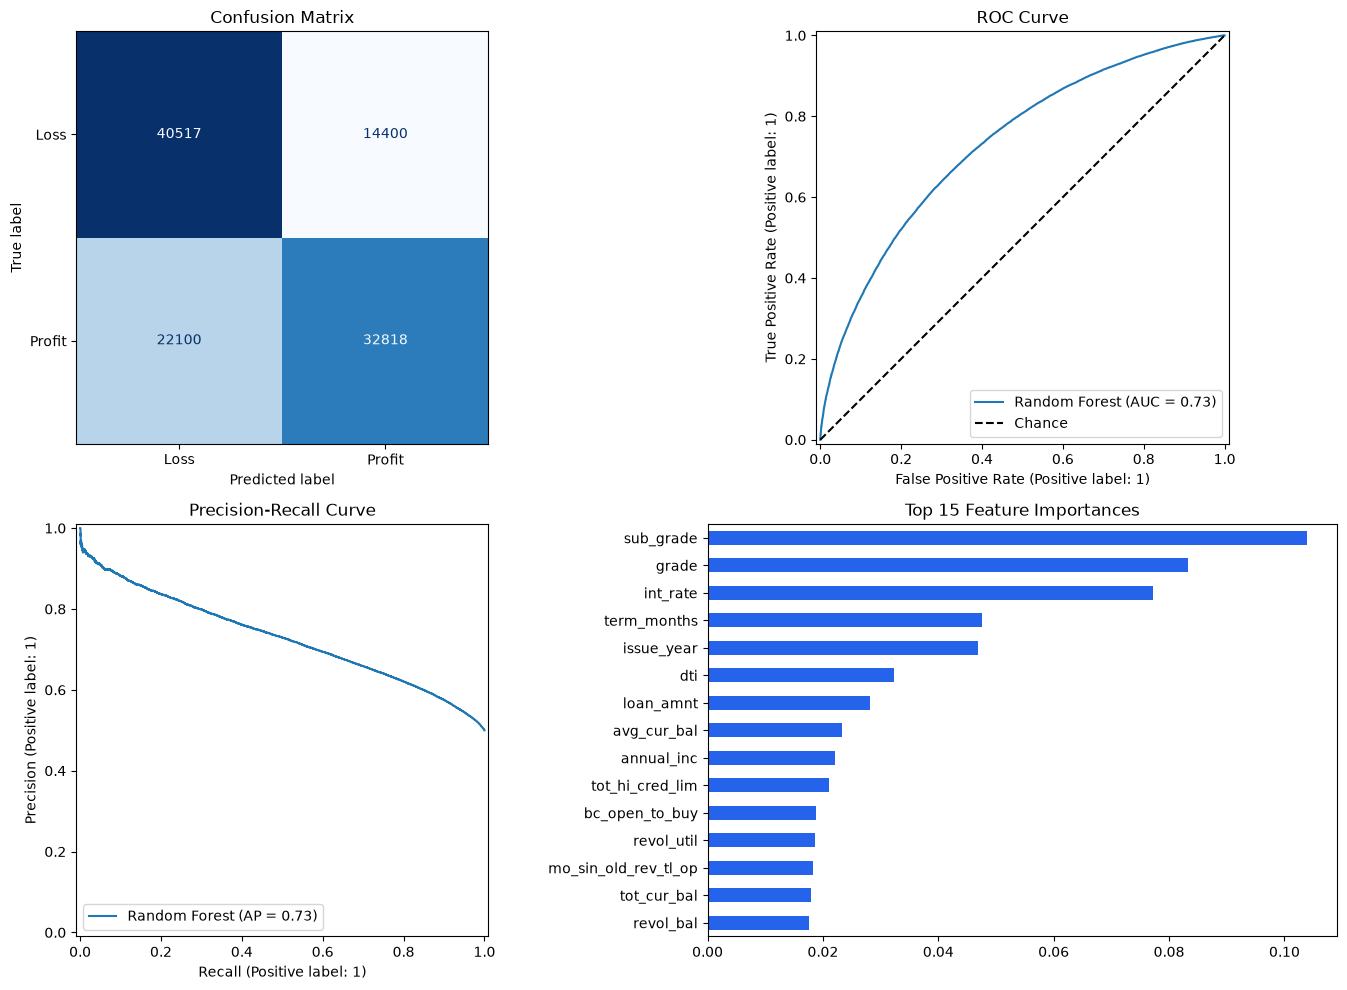

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, display_labels=["Loss", "Profit"], cmap="Blues", colorbar=False, ax=axes[0, 0])
axes[0, 0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, test_probability, name="Random Forest", ax=axes[0, 1])
axes[0, 1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0, 1].legend()
axes[0, 1].set_title("ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, test_probability, name="Random Forest", ax=axes[1, 0])
axes[1, 0].set_title("Precision-Recall Curve")
feature_importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(15).sort_values()
feature_importance.plot(kind="barh", color="#2563eb", ax=axes[1, 1])
axes[1, 1].set_title("Top 15 Feature Importances")
plt.tight_layout()
plt.show()